In [1]:
# Compute RSI
def compute_rsi(series, period=14):
    delta = series.diff(1)
    gain = delta.where(delta > 0, 0)
    loss = -delta.where(delta < 0, 0)
    avg_gain = gain.rolling(window=period).mean()
    avg_loss = loss.rolling(window=period).mean()
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

# Compute MACD
def compute_macd(series, short_period=12, long_period=26, signal_period=9):
    short_ema = series.ewm(span=short_period, adjust=False).mean()
    long_ema = series.ewm(span=long_period, adjust=False).mean()
    macd = short_ema - long_ema
    macd_signal = macd.ewm(span=signal_period, adjust=False).mean()
    return macd, macd_signal

c:\Users\Asad\AppData\Local\Programs\Python\Python312\Lib\site-packages\yfinance\scrapers\history.py:239: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  quotes2 = quotes.resample('30T')
[*********************100%%**********************]  1 of 1 completed


Historical data range: 2024-06-24 09:00:00 to 2024-06-28 16:30:00
Number of data points: 60
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 291ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/

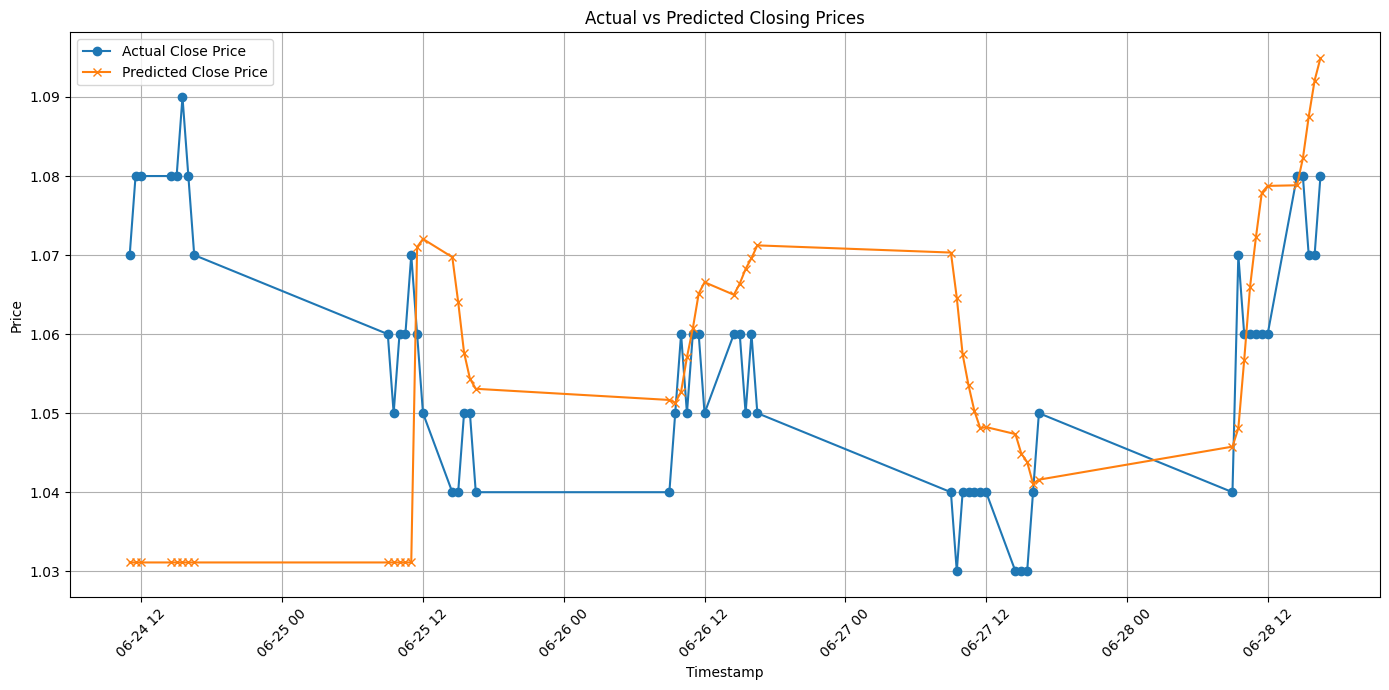

(10000,
 10482.571843028069,
 [('buy', 9433.0, 1.059999942779541),
  ('buy', 0.0, 1.0499999523162842),
  ('buy', 0.0, 1.0399999618530273),
  ('buy', 0.0, 1.0399999618530273),
  ('buy', 0.0, 1.0499999523162842),
  ('buy', 0.0, 1.0499999523162842),
  ('buy', 0.0, 1.0399999618530273),
  ('buy', 0.0, 1.0399999618530273),
  ('buy', 0.0, 1.0499999523162842),
  ('sell', 9433.0, 1.059999942779541),
  ('buy', 9523.0, 1.0499999523162842),
  ('buy', 0.0, 1.059999942779541),
  ('buy', 0.0, 1.059999942779541),
  ('buy', 0.0, 1.0499999523162842),
  ('buy', 0.0, 1.059999942779541),
  ('buy', 0.0, 1.059999942779541),
  ('buy', 0.0, 1.0499999523162842),
  ('buy', 0.0, 1.059999942779541),
  ('buy', 0.0, 1.0499999523162842),
  ('buy', 0.0, 1.0399999618530273),
  ('buy', 0.0, 1.0299999713897705),
  ('buy', 0.0, 1.0399999618530273),
  ('buy', 0.0, 1.0399999618530273),
  ('buy', 0.0, 1.0399999618530273),
  ('buy', 0.0, 1.0399999618530273),
  ('buy', 0.0, 1.0399999618530273),
  ('buy', 0.0, 1.029999971389770

In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
import joblib
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt

SEQ_LENGTH = 4

# Function to fetch data from Yahoo Finance
def fetch_data(stock_code, interval='4h', start_date='2023-06-23', end_date='2023-06-30'):
    data = yf.download(stock_code, interval=interval, start=start_date, end=end_date)
    data['RSI'] = compute_rsi(data['Close'])
    data['MACD'], data['MACD_Signal'] = compute_macd(data['Close'])
    return data

# Function to compute RSI (example implementation)
def compute_rsi(data, window=14):
    delta = data.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

# Function to compute MACD (example implementation)
def compute_macd(data, slow=26, fast=12, signal=9):
    exp1 = data.ewm(span=fast, adjust=False).mean()
    exp2 = data.ewm(span=slow, adjust=False).mean()
    macd = exp1 - exp2
    signal_line = macd.ewm(span=signal, adjust=False).mean()
    return macd, signal_line

# Function to preprocess data for prediction
def preprocess_data_for_prediction(data, scaler):
    # Add missing columns with default values
    required_columns = ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']
    for col in required_columns:
        if col not in data.columns:
            data[col] = 0
    data_scaled = scaler.transform(data[required_columns])
    return data_scaled

# Function to predict the next closing price
def predict_next_closing_price(model, scaler, data_for_prediction):
    # Preprocess data for prediction
    data_for_prediction = preprocess_data_for_prediction(data_for_prediction, scaler)
    data_for_prediction = np.array([data_for_prediction])  # Reshape to 3D array
    
    # Predict with the model
    predicted_price_scaled = model.predict(data_for_prediction)
    
    # Construct a dummy array to mimic the original feature structure
    features_dummy = np.zeros((predicted_price_scaled.shape[0], 7))
    features_dummy[:, 3] = predicted_price_scaled[:, 0]  # Assuming 'Close' is the 4th column
    
    # Inverse transform to get the actual predicted price
    predicted_price = scaler.inverse_transform(features_dummy)[:, 3]
    
    # Extract the scalar value from the array
    predicted_price = predicted_price[0]
    
    return predicted_price

# Function to execute trading strategy
def execute_trading(model, scaler, historical_data):
    initial_cash = 10000  # Example starting cash
    cash = initial_cash
    shares = 0
    transactions = []

    if historical_data.empty or len(historical_data) < SEQ_LENGTH:
        raise ValueError("Not enough data to perform backtesting.")

    for i in range(len(historical_data) - SEQ_LENGTH):
        current_data = historical_data.iloc[i:i+SEQ_LENGTH]
        data_for_prediction = current_data[['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']]
        
        if len(data_for_prediction) == SEQ_LENGTH:
            predicted_price = predict_next_closing_price(model, scaler, data_for_prediction)
            current_price = historical_data['Close'].iloc[i + SEQ_LENGTH]
            
            # Example trading logic: buy if predicted price is higher than current price
            if predicted_price > current_price and cash > 0:
                shares_to_buy = cash // current_price
                cash -= shares_to_buy * current_price
                shares += shares_to_buy
                transactions.append(('buy', shares_to_buy, current_price))
            
            # Sell if predicted price is lower than current price
            elif predicted_price < current_price and shares > 0:
                cash += shares * current_price
                transactions.append(('sell', shares, current_price))
                shares = 0
    
    final_portfolio_value = cash + shares * historical_data['Close'].iloc[-1]
    return initial_cash, final_portfolio_value, transactions

def backtest_trading_strategy(stock_code, model_path, scaler_path, start_date, end_date):
    model = load_model(model_path)
    scaler = joblib.load(scaler_path)
    
    # Fetch historical data for the backtest period
    historical_data = fetch_data(stock_code, interval='30m', start_date=start_date, end_date=end_date)
    
    # Debug print to check the data range
    print(f"Historical data range: {historical_data.index.min()} to {historical_data.index.max()}")
    print(f"Number of data points: {len(historical_data)}")
    
    # Execute trading strategy
    initial_cash, final_portfolio_value, transactions = execute_trading(model, scaler, historical_data)
    
    # Calculate returns
    returns = (final_portfolio_value - initial_cash) / initial_cash
    
    # Print results
    print(f"Initial Cash: {initial_cash}")
    print(f"Final Portfolio Value: {final_portfolio_value}")
    print(f"Returns: {returns * 100:.2f}%")
    print(f"Transactions: {transactions}")
    
    # Prepare data for plotting
    predicted_prices = []
    actual_prices = []
    timestamps = []
    for i in range(len(historical_data) - SEQ_LENGTH):
        current_data = historical_data.iloc[i:i+SEQ_LENGTH]
        data_for_prediction = current_data[['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']]
        
        if len(data_for_prediction) == SEQ_LENGTH:
            predicted_price = predict_next_closing_price(model, scaler, data_for_prediction)
            actual_price = historical_data['Close'].iloc[i + SEQ_LENGTH]
            timestamp = historical_data.index[i + SEQ_LENGTH]
            
            predicted_prices.append(predicted_price)
            actual_prices.append(actual_price)
            timestamps.append(timestamp)
    
    # Plotting predicted vs actual prices
    plt.figure(figsize=(14, 7))
    plt.plot(timestamps, actual_prices, label='Actual Close Price', marker='o')
    plt.plot(timestamps, predicted_prices, label='Predicted Close Price', marker='x')
    plt.title('Actual vs Predicted Closing Prices')
    plt.xlabel('Timestamp')
    plt.ylabel('Price')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return initial_cash, final_portfolio_value, transactions

# Fetch data for the backtesting period
stock_code = '5148.KL'
start_date = '2024-06-23'
end_date = '2024-06-30'

# Perform backtesting
backtest_trading_strategy(stock_code, 'model.keras', 'scaler.pkl', start_date, end_date)
